# Week 12 Lab Work

**Dataset:** Adult / Census Income (UCI Machine Learning Repository)

1. Load the same pre-processed dataset as the last lab works.
2. Reproduce the two-neuron SOM example from the slides.
3. Scale the features, build a Kohonen Self-Organizing Map (SOM) in numpy and train it on all rows.
4. Show the U-matrix, the hit map and the share of `>50K` rows on each neuron.
5. Group the neurons with K-means and pick the number of clusters by silhouette score.
6. Compare the grid sizes 5 x 5, 10 x 10 and 15 x 15.
7. Draw the clusters and the neuron grid in PCA space.
8. Write the conclusions.

In [1]:
import os
import urllib.request

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

cols = ["age", "workclass", "fnlwgt", "education", "education-num",
        "marital-status", "occupation", "relationship", "race", "sex",
        "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"]


def get_file(data_filename):
    for base in [".", ".."]:
        if not os.path.isdir(base):
            continue
        for root, dirs, files in os.walk(base):
            if data_filename in files:
                return os.path.join(root, data_filename)

    print(f"'{data_filename}' not found in the workspace. Downloading it dynamically...")
    url = f"https://archive.ics.uci.edu/ml/machine-learning-databases/adult/{data_filename}"
    urllib.request.urlretrieve(url, data_filename)
    return data_filename


# 1. Load and pre-process the data
path = get_file("adult.data")
print(f"Loading data from: {path}")
df = pd.read_csv(path, header=None, names=cols, skipinitialspace=True, na_values="?")
df = df.dropna().drop_duplicates().reset_index(drop=True)
df["income"] = (df["income"] == ">50K").astype(int)
df = pd.get_dummies(df, drop_first=True)

print("Shape:", df.shape)
print("Missing cells:", df.isnull().sum().sum())

'adult.data' not found in the workspace. Downloading it dynamically...


Loading data from: adult.data
Shape: (30139, 97)
Missing cells: 0


## 2. Slide example: two-neuron SOM

Four training samples, two neurons, learning rate 0.5 and 3 epochs. Only the winner (smallest squared Euclidean distance) moves toward the sample.

In [2]:
T = np.array([[1, 1, 0, 0], [0, 0, 0, 1], [1, 0, 0, 0], [0, 0, 1, 1]], float)
W = np.array([[0.2, 0.6, 0.5, 0.9], [0.8, 0.4, 0.7, 0.3]])
alpha = 0.5

for epoch in range(3):
    for s in T:
        k = np.argmin(((W - s) ** 2).sum(axis=1))
        W[k] += alpha * (s - W[k])

test = np.array([0, 0, 0, 1])
k = np.argmin(((W - test) ** 2).sum(axis=1))
print("Trained weights:")
print(W.round(6))
print(f"Test sample {test.tolist()} belongs to neuron {k}")

Trained weights:
[[0.003125 0.009375 0.664062 0.998438]
 [0.996875 0.334375 0.010938 0.004688]]
Test sample [0, 0, 0, 1] belongs to neuron 0


## 3. Scale the features and build the SOM

`income` is kept out of the training features. It is used only later to read the map. `MinMaxScaler` puts every feature in the range 0 to 1, so no feature dominates the distance. `minisom` is not installed, so the SOM is written in numpy. The map is trained on all rows with one random sample per step. The learning rate and the neighbourhood radius shrink during training. The quantization error is the mean distance from a row to its best neuron. The topographic error is the share of rows whose best and second-best neurons are not neighbours on the grid (8 neighbours).

In [3]:
import time

X = MinMaxScaler().fit_transform(df.drop(columns=["income"]))
y = df["income"].to_numpy()


def dist2(X, w):
    return (X ** 2).sum(1)[:, None] - 2 * X @ w.T + (w ** 2).sum(1)[None, :]


def train_som(X, rows, cols, iters=20000, lr0=0.5, log=500, seed=42):
    rng = np.random.default_rng(seed)
    w = X[rng.choice(len(X), rows * cols, replace=False)].copy()
    gy, gx = np.divmod(np.arange(rows * cols), cols)
    sigma0 = max(rows, cols) / 2
    hist = []
    for t in range(iters):
        decay = np.exp(-t / iters)
        x = X[rng.integers(len(X))]
        b = ((w - x) ** 2).sum(1).argmin()
        h = np.exp(-((gy - gy[b]) ** 2 + (gx - gx[b]) ** 2) / (2 * (sigma0 * decay) ** 2))
        w += lr0 * decay * h[:, None] * (x - w)
        if t % log == 0:
            hist.append((t, np.sqrt(np.maximum(dist2(X, w).min(1), 0)).mean()))
    return w, hist


def quant_error(X, w):
    return np.sqrt(np.maximum(dist2(X, w).min(1), 0)).mean()


def topo_error(X, w, cols):
    top2 = np.argsort(dist2(X, w), axis=1)[:, :2]
    dy = np.abs(top2[:, 0] // cols - top2[:, 1] // cols)
    dx = np.abs(top2[:, 0] % cols - top2[:, 1] % cols)
    return (np.maximum(dy, dx) > 1).mean()


print("Features:", X.shape[1], "| Rows:", len(X))

Features: 96 | Rows: 30139


## 4. Train a 10 x 10 map

The map is trained for 20000 iterations on all rows. The quantization error is measured on all rows every 500 iterations.

Training time: 2.0 s
Quantization error: 1.5666
Topographic error:  0.0340


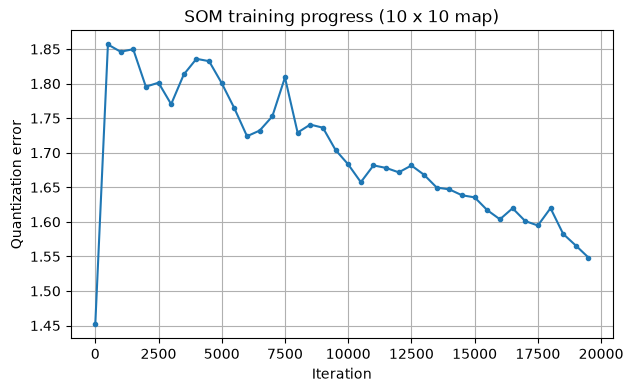

Error at iteration 0: 1.4515 | maximum: 1.8566 | last logged: 1.5484


In [4]:
t0 = time.time()
w, hist = train_som(X, 10, 10)
print(f"Training time: {time.time() - t0:.1f} s")
print(f"Quantization error: {quant_error(X, w):.4f}")
print(f"Topographic error:  {topo_error(X, w, 10):.4f}")

steps, errs = zip(*hist)
plt.figure(figsize=(7, 4))
plt.plot(steps, errs, marker="o", markersize=3)
plt.xlabel("Iteration")
plt.ylabel("Quantization error")
plt.title("SOM training progress (10 x 10 map)")
plt.grid(True)
plt.show()
print(f"Error at iteration 0: {errs[0]:.4f} | maximum: {max(errs):.4f} | last logged: {errs[-1]:.4f}")

## 5. U-matrix, hit map and `>50K` share per neuron

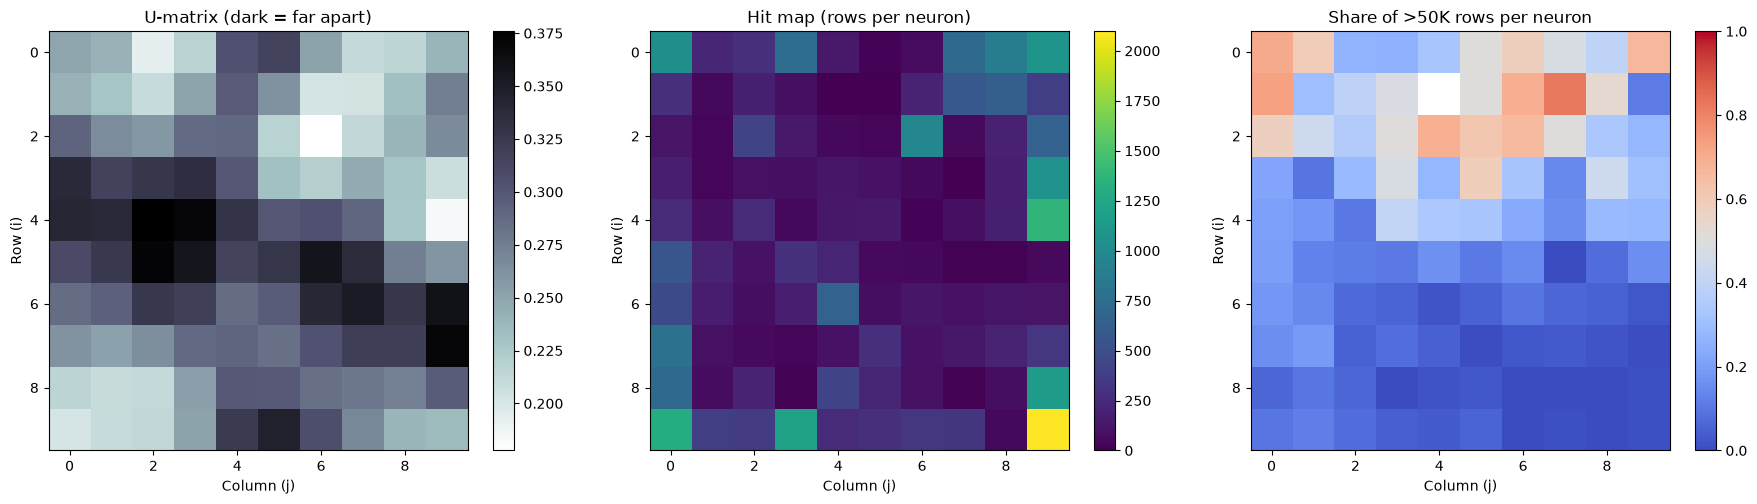

Empty neurons: 1 of 100
U-matrix: min 0.178, max 0.376, mean 0.277
Hits per neuron: max 2098, mean 301.4
Overall >50K share: 0.249
Neuron >50K share: min 0.000, max 0.822
Neurons with >50K share above 0.5: 14
Neurons with >50K share below 0.1: 37
Rows on neurons with share above 0.5: 5523 of 30139


In [5]:
R, C = 10, 10
bmu = dist2(X, w).argmin(1)
wg = w.reshape(R, C, -1)
umat = np.zeros((R, C))
for i in range(R):
    for j in range(C):
        nb = [(i + a, j + b) for a, b in [(-1, 0), (1, 0), (0, -1), (0, 1)]
              if 0 <= i + a < R and 0 <= j + b < C]
        umat[i, j] = np.mean([np.linalg.norm(wg[i, j] - wg[p]) for p in nb])

hits = np.bincount(bmu, minlength=R * C)
pos = np.bincount(bmu, weights=y, minlength=R * C)
share = np.where(hits > 0, pos / np.maximum(hits, 1), np.nan)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, data, cmap, title, kw in [
        (ax[0], umat, "bone_r", "U-matrix (dark = far apart)", {}),
        (ax[1], hits.reshape(R, C), "viridis", "Hit map (rows per neuron)", {}),
        (ax[2], share.reshape(R, C), "coolwarm", "Share of >50K rows per neuron", {"vmin": 0, "vmax": 1})]:
    im = a.imshow(data, cmap=cmap, **kw)
    a.set_title(title)
    a.set_xlabel("Column (j)")
    a.set_ylabel("Row (i)")
    fig.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout()
plt.show()

print(f"Empty neurons: {(hits == 0).sum()} of {R * C}")
print(f"U-matrix: min {umat.min():.3f}, max {umat.max():.3f}, mean {umat.mean():.3f}")
print(f"Hits per neuron: max {hits.max()}, mean {hits.mean():.1f}")
print(f"Overall >50K share: {y.mean():.3f}")
print(f"Neuron >50K share: min {np.nanmin(share):.3f}, max {np.nanmax(share):.3f}")
print("Neurons with >50K share above 0.5:", int((share > 0.5).sum()))
print("Neurons with >50K share below 0.1:", int((share < 0.1).sum()))
print(f"Rows on neurons with share above 0.5: {int(hits[share > 0.5].sum())} of {len(X)}")

## 6. Group the neurons into clusters

The 100 neuron weight vectors are grouped with K-means for k = 2 to 8. Every row gets the group of its best neuron. The silhouette score uses a random sample of 5000 rows (`random_state=42`) because all rows are too many.

In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

res, groups = [], {}
for k in range(2, 9):
    g = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(w)
    groups[k] = g
    res.append({"k": k, "Silhouette": silhouette_score(X, g[bmu], sample_size=5000, random_state=42)})

ks = pd.DataFrame(res).set_index("k")
display(ks.round(5))
k_best = ks["Silhouette"].idxmax()
print(f"k chosen by silhouette score: {k_best}")

lab = groups[k_best][bmu]
sizes = np.bincount(lab)
table = pd.DataFrame({
    "Cluster": range(len(sizes)),
    "Size": sizes,
    "Share (%)": (sizes / len(X) * 100).round(2),
    ">50K Rate (%)": [round(y[lab == c].mean() * 100, 2) for c in range(len(sizes))],
}).set_index("Cluster")
display(table)

,Silhouette
k,
2,0.13296
3,0.13298
4,0.10593
5,0.11562
6,0.07487
7,0.07682
8,0.08453


k chosen by silhouette score: 3


,Size,Share (%),>50K Rate (%)
Cluster,,,
0,8294,27.52,10.45
1,14529,48.21,44.53
2,7316,24.27,2.31


## 7. Compare grid sizes

Each grid is trained with the same settings. Every neuron is treated as one cluster for the cluster scores. The silhouette score uses the same 5000-row sample as before. Adjusted Rand Index and Normalized Mutual Information compare the neurons with `income`.

In [7]:
from sklearn.metrics import davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score

rows_out = []
for r, c in [(5, 5), (10, 10), (15, 15)]:
    t0 = time.time()
    wi, _ = train_som(X, r, c)
    secs = time.time() - t0
    b = dist2(X, wi).argmin(1)
    rows_out.append({
        "Grid": f"{r} x {c}",
        "Neurons Used": len(np.unique(b)),
        "Quantization Error": quant_error(X, wi),
        "Topographic Error": topo_error(X, wi, c),
        "Silhouette": silhouette_score(X, b, sample_size=5000, random_state=42),
        "Davies-Bouldin": davies_bouldin_score(X, b),
        "Adjusted Rand Index": adjusted_rand_score(y, b),
        "Normalized Mutual Info": normalized_mutual_info_score(y, b),
        "Time (s)": secs,
    })

grid_cmp = pd.DataFrame(rows_out).set_index("Grid")
display(grid_cmp.round(4))

,Neurons Used,Quantization Error,Topographic Error,Silhouette,Davies-Bouldin,Adjusted Rand Index,Normalized Mutual Info,Time (s)
Grid,,,,,,,,
5 x 5,25,1.6065,0.0413,0.0734,3.2672,0.0152,0.0799,0.9179
10 x 10,99,1.5666,0.0340,0.0460,3.7561,0.0109,0.0690,2.0479
15 x 15,215,1.5443,0.0149,0.0105,3.4467,0.0056,0.0630,3.4927


## 8. PCA view

A fixed sample of 3000 rows is drawn. PCA is fitted on all rows. The neuron grid is drawn in the same two dimensions to show how the map is folded.

Explained variance of PC1 and PC2: [0.1472 0.0837] | total 0.231


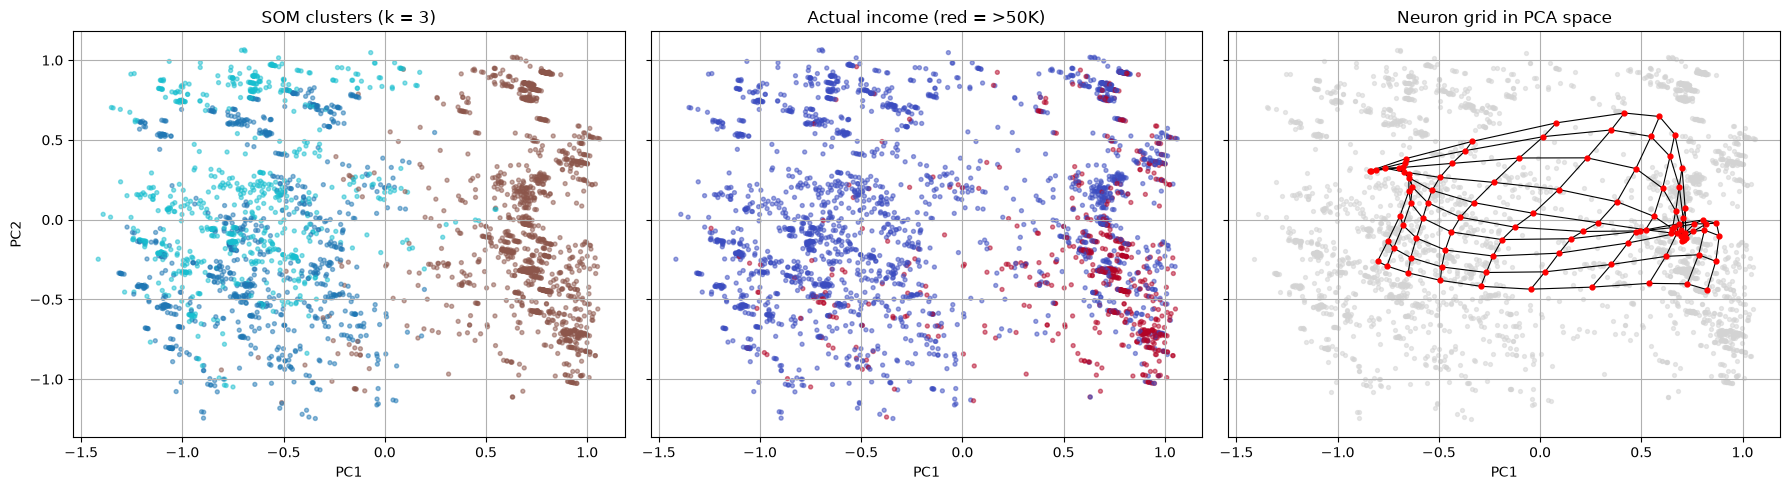

In [8]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42).fit(X)
sidx = np.random.default_rng(42).choice(len(X), 3000, replace=False)
pts = pca.transform(X[sidx])
nodes = pca.transform(w).reshape(R, C, 2)
print("Explained variance of PC1 and PC2:", pca.explained_variance_ratio_.round(4), "| total", round(pca.explained_variance_ratio_.sum(), 4))

fig, ax = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
ax[0].scatter(pts[:, 0], pts[:, 1], c=lab[sidx], cmap="tab10", alpha=0.5, s=8)
ax[0].set_title(f"SOM clusters (k = {k_best})")
ax[1].scatter(pts[:, 0], pts[:, 1], c=y[sidx], cmap="coolwarm", alpha=0.5, s=8)
ax[1].set_title("Actual income (red = >50K)")
ax[2].scatter(pts[:, 0], pts[:, 1], color="lightgray", alpha=0.5, s=8)
for i in range(R):
    ax[2].plot(nodes[i, :, 0], nodes[i, :, 1], color="black", lw=0.8)
for j in range(C):
    ax[2].plot(nodes[:, j, 0], nodes[:, j, 1], color="black", lw=0.8)
ax[2].scatter(nodes[..., 0], nodes[..., 1], color="red", s=12, zorder=3)
ax[2].set_title("Neuron grid in PCA space")
for a in ax:
    a.set_xlabel("PC1")
    a.grid(True)
ax[0].set_ylabel("PC2")
plt.tight_layout()
plt.show()

## 9. Conclusions

- **Slide example:** the two-neuron SOM gives the trained weights [0.003125, 0.009375, 0.664062, 0.998438] and [0.996875, 0.334375, 0.010938, 0.004688]. The test sample [0, 0, 0, 1] goes to neuron 0. This matches the slides, so the winner search and the update rule are correct.
- **Training:** the 10 x 10 map was trained on all 30139 rows. The quantization error starts at 1.4515, rises to 1.8566 while the radius is still large, and ends at 1.5666. The topographic error is 0.0340, so for about 97% of the rows the two best neurons are neighbours on the grid. The map keeps the shape of the data well. The error stays high because the data has 96 features, most of them one-hot columns.
- **Map:** the U-matrix goes from 0.178 to 0.376 (mean 0.277). Only 1 of 100 neurons is empty. The `>50K` share per neuron goes from 0.000 to 0.822 (overall 0.249). 14 neurons have more than 50% `>50K` rows and hold 5523 rows. 37 neurons have less than 10% `>50K` rows. Income was not used for training, yet high-income rows gather in one area of the map.
- **Clusters:** K-means on the neurons gives the best silhouette at k = 3 (0.13298). k = 2 is almost the same (0.13296) and k = 4 to 8 are lower (0.07487 to 0.11562). The three clusters have 8294 rows (27.52%, 10.45% `>50K`), 14529 rows (48.21%, 44.53% `>50K`) and 7316 rows (24.27%, 2.31% `>50K`). The silhouette values are low, so the groups are not sharply separated. They still split the rows into a low-income, a mixed and a high-income group.
- **Grid size:** a larger grid fits the data better. The quantization error goes down (1.6065, 1.5666, 1.5443) and the topographic error goes down (0.0413, 0.0340, 0.0149) for 5 x 5, 10 x 10 and 15 x 15. The 15 x 15 map uses 215 of 225 neurons. But the silhouette falls (0.0734, 0.0460, 0.0105), and the Adjusted Rand Index (0.0152, 0.0109, 0.0056) and the NMI (0.0799, 0.0690, 0.0630) also fall. Many small neurons agree less with `income` than a few large ones. The 10 x 10 map is a good middle choice.
- **PCA:** PC1 and PC2 explain only 23.1% of the variance, so the 2D picture is a rough view. The neuron grid is folded over the point cloud and the income colors overlap. The classes overlap, so a SOM is good to explore the data but is not a classifier.